In [3]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.10.0


In [4]:
#import numpy as np
#import panda as pd

In [5]:
#!pip install pandas

In [6]:
import numpy as np
import pandas as pd

In [7]:
from pathlib import Path
import tarfile
import shutil

# Folder containing the two downloaded archives
data_folder = Path(
    r"C:\Users\reema\Downloads\Problem-4_Graph_Representation_Learning_and_Node_Classification-20261106T154625Z-1-001"
) / "Problem-4_Graph_Representation_Learning_and_Node_Classification"

# Extract the three files we need from each archive
for dataset in ["cora", "citeseer"]:
    output_folder = data_folder / dataset
    output_folder.mkdir(exist_ok=True)

    with tarfile.open(data_folder / f"{dataset}.tgz", "r:gz") as archive:
        for filename in ["README", f"{dataset}.content", f"{dataset}.cites"]:
            source = archive.extractfile(f"{dataset}/{filename}")
            with source, open(output_folder / filename, "wb") as destination:
                shutil.copyfileobj(source, destination)

    print(f"{dataset}: extracted successfully")

cora: extracted successfully
citeseer: extracted successfully


In [8]:
import numpy as np

# Load paper information as text to preserve IDs and topic names
cora_content = np.loadtxt(
    data_folder / "cora" / "cora.content",
    dtype=str
)

# Separate IDs, word features, and topic labels
paper_ids = cora_content[:, 0]
features = cora_content[:, 1:-1].astype(np.float32)
labels = cora_content[:, -1]

# Load citation links
citations = np.loadtxt(
    data_folder / "cora" / "cora.cites",
    dtype=str
)

print("Number of papers:", len(paper_ids))
print("Features per paper:", features.shape[1])
print("Number of topic classes:", len(np.unique(labels)))
print("Number of citation rows:", len(citations))
print("\nFirst paper ID:", paper_ids[0])
print("First paper topic:", labels[0])
print("\nTopic classes:", np.unique(labels))

Number of papers: 2708
Features per paper: 1433
Number of topic classes: 7
Number of citation rows: 5429

First paper ID: 31336
First paper topic: Neural_Networks

Topic classes: ['Case_Based' 'Genetic_Algorithms' 'Neural_Networks'
 'Probabilistic_Methods' 'Reinforcement_Learning' 'Rule_Learning' 'Theory']


In [9]:
# Map paper IDs to row numbers: 0, 1, ..., 2707
id_to_index = {
    paper_id: index
    for index, paper_id in enumerate(paper_ids)
}

# Create an empty set of neighbors for every paper
neighbors = [set() for _ in paper_ids]

# Add citation links in both directions
for cited_id, citing_id in citations:
    cited_index = id_to_index[cited_id]
    citing_index = id_to_index[citing_id]

    # Skip links from a paper to itself
    if cited_index != citing_index:
        neighbors[cited_index].add(citing_index)
        neighbors[citing_index].add(cited_index)

# Each undirected edge appears in two neighbor sets
num_edges = sum(len(node_neighbors) for node_neighbors in neighbors) // 2

print("Number of nodes:", len(neighbors))
print("Number of unique undirected edges:", num_edges)
print("Neighbors of the first paper:", sorted(neighbors[0]))

Number of nodes: 2708
Number of unique undirected edges: 5278
Neighbors of the first paper: [8, 14, 258, 435, 544]


In [10]:
# Get the topic names in alphabetical order
class_names = np.unique(labels)

# Map each topic to a number
class_to_index = {
    topic: index
    for index, topic in enumerate(class_names)
}

# Convert every paper's topic into its numeric label
y = np.array([class_to_index[topic] for topic in labels])

print("Topic mapping:")
for topic, index in class_to_index.items():
    print(f"{index}: {topic}")

print("\nFirst paper's topic:", labels[0])
print("First paper's numeric label:", y[0])
print("Label array shape:", y.shape)

Topic mapping:
0: Case_Based
1: Genetic_Algorithms
2: Neural_Networks
3: Probabilistic_Methods
4: Reinforcement_Learning
5: Rule_Learning
6: Theory

First paper's topic: Neural_Networks
First paper's numeric label: 2
Label array shape: (2708,)


In [11]:
from sklearn.model_selection import train_test_split

# Row indices of all papers
node_indices = np.arange(len(y))

# Reserve 20% for final testing
train_val_indices, test_indices = train_test_split(
    node_indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the remaining 80% into 60% training and 20% validation
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.25,
    random_state=42,
    stratify=y[train_val_indices]
)

print("Training papers:", len(train_indices))
print("Validation papers:", len(val_indices))
print("Test papers:", len(test_indices))

Training papers: 1624
Validation papers: 542
Test papers: 542


In [12]:
#%pip install scikit-learn

In [13]:
import random

def random_walk(start_node, walk_length, rng):
    walk = [start_node]

    while len(walk) < walk_length:
        current_node = walk[-1]
        possible_neighbors = sorted(neighbors[current_node])

        # Stop if the current node has no neighbors
        if not possible_neighbors:
            break

        next_node = rng.choice(possible_neighbors)
        walk.append(next_node)

    return walk

# Generate a repeatable example containing 10 nodes
example_walk = random_walk(
    start_node=0,
    walk_length=10,
    rng=random.Random(42)
)

print("Example random walk:", example_walk)

Example random walk: [0, 8, 0, 258, 14, 384, 14, 232, 613, 2496]


In [14]:
# Repeatable random choices
walk_rng = random.Random(42)

num_walks_per_node = 10
walk_length = 40

walks = []
nodes = list(range(len(neighbors)))

for _ in range(num_walks_per_node):
    walk_rng.shuffle(nodes)

    for node in nodes:
        walk = random_walk(node, walk_length, walk_rng)

        # Store node indices as strings for the embedding model
        walks.append([str(index) for index in walk])

print("Total walks:", len(walks))
print("Length of first walk:", len(walks[0]))
print("First walk (first 10 nodes):", walks[0][:10])

Total walks: 27080
Length of first walk: 40
First walk (first 10 nodes): ['1698', '2597', '2256', '2597', '2256', '2597', '2256', '2597', '2256', '2597']


In [15]:
#%pip install gensim

In [16]:
from gensim.models import Word2Vec

In [17]:
embedding_model = Word2Vec(
    sentences=walks,
    vector_size=64,   # Numbers in each paper's vector
    window=5,         # Nearby nodes used as context
    min_count=0,      # Keep every node
    sg=1,            # Use Skip-gram
    hs=1,            # Use hierarchical softmax
    negative=0,      # Disable negative sampling
    workers=1,       # Help make results reproducible
    seed=42,
    epochs=5
)

# Arrange vectors in the same row order as features and labels
deepwalk_embeddings = np.array([
    embedding_model.wv[str(node)]
    for node in range(len(neighbors))
])

print("Embedding matrix shape:", deepwalk_embeddings.shape)
print("First paper's vector (first 10 values):")
print(deepwalk_embeddings[0][:10])

Embedding matrix shape: (2708, 64)
First paper's vector (first 10 values):
[-0.35305414 -1.2135878  -1.4884111  -0.3656545   0.26283875 -0.24369459
 -0.23518264 -0.42333597  0.15637799 -0.5464813 ]


In [18]:
import sys
import gensim
import numpy as np
import scipy

print("Python:", sys.version)
print("Gensim:", gensim.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)

Python: 3.10.13 | packaged by Anaconda, Inc. | (main, Sep 11 2023, 13:15:57) [MSC v.1916 64 bit (AMD64)]
Gensim: 4.3.3
NumPy: 1.26.4
SciPy: 1.13.1


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

# Train using only the training papers and their labels
deepwalk_classifier = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    random_state=42
)

deepwalk_classifier.fit(
    deepwalk_embeddings[train_indices],
    y[train_indices]
)

# Evaluate on validation papers
val_predictions = deepwalk_classifier.predict(
    deepwalk_embeddings[val_indices]
)

val_probabilities = deepwalk_classifier.predict_proba(
    deepwalk_embeddings[val_indices]
)

val_accuracy = accuracy_score(y[val_indices], val_predictions)

val_auc = roc_auc_score(
    y[val_indices],
    val_probabilities,
    multi_class="ovr",
    average="macro"
)

print(f"DeepWalk validation accuracy: {val_accuracy:.4f}")
print(f"DeepWalk validation AUC: {val_auc:.4f}")

DeepWalk validation accuracy: 0.7970
DeepWalk validation AUC: 0.9558


In [20]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.10.0


In [21]:
import scipy.sparse as sp

# 1. Normalize each paper's word features
# Each nonempty row will sum to 1
row_sums = features.sum(axis=1, keepdims=True)
normalized_features = features / np.maximum(row_sums, 1)

# 2. Build the adjacency matrix from our neighbor lists
rows = []
cols = []

for node, node_neighbors in enumerate(neighbors):
    for neighbor in sorted(node_neighbors):
        rows.append(node)
        cols.append(neighbor)

num_nodes = len(neighbors)

adjacency = sp.csr_matrix(
    (np.ones(len(rows), dtype=np.float32), (rows, cols)),
    shape=(num_nodes, num_nodes)
)

# 3. Add self-connections so each paper includes its own information
adjacency_self = adjacency + sp.eye(
    num_nodes, dtype=np.float32, format="csr"
)

# 4. Normalize connections using node degrees
degrees = np.asarray(adjacency_self.sum(axis=1)).ravel()
degree_matrix = sp.diags(1.0 / np.sqrt(degrees))

normalized_adjacency = (
    degree_matrix @ adjacency_self @ degree_matrix
).tocoo()

# 5. Convert to TensorFlow tensors
X_tf = tf.convert_to_tensor(
    normalized_features, dtype=tf.float32
)

A_tf = tf.sparse.reorder(
    tf.SparseTensor(
        indices=np.column_stack([
            normalized_adjacency.row,
            normalized_adjacency.col
        ]).astype(np.int64),
        values=normalized_adjacency.data.astype(np.float32),
        dense_shape=normalized_adjacency.shape
    )
)

print("Feature matrix shape:", X_tf.shape)
print("Adjacency matrix shape:", A_tf.shape)
print("Stored adjacency entries:", len(normalized_adjacency.data))

Feature matrix shape: (2708, 1433)
Adjacency matrix shape: (2708, 2708)
Stored adjacency entries: 13264


In [22]:
# Set random seeds before creating the model
tf.keras.utils.set_random_seed(42)

class GCN(tf.keras.Model):
    def __init__(self, num_classes):
        super().__init__()

        self.dropout = tf.keras.layers.Dropout(0.5)

        self.hidden_layer = tf.keras.layers.Dense(
            16,
            use_bias=False,
            kernel_regularizer=tf.keras.regularizers.l2(5e-4)
        )

        self.output_layer = tf.keras.layers.Dense(
            num_classes,
            use_bias=False
        )

    def call(self, inputs, training=False):
        node_features, graph = inputs

        # First graph convolution
        x = self.dropout(node_features, training=training)
        x = self.hidden_layer(x)
        x = tf.sparse.sparse_dense_matmul(graph, x)
        x = tf.nn.relu(x)

        # Second graph convolution
        x = self.dropout(x, training=training)
        x = self.output_layer(x)
        logits = tf.sparse.sparse_dense_matmul(graph, x)

        return logits


gcn_model = GCN(num_classes=len(class_names))

# Run one forward pass to create the model's weights
initial_logits = gcn_model((X_tf, A_tf), training=False)

print("Output shape:", initial_logits.shape)
gcn_model.summary()

Output shape: (2708, 7)
Model: "gcn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dropout (Dropout)           multiple                  0         
                                                                 
 dense (Dense)               multiple                  22928     
                                                                 
 dense_1 (Dense)             multiple                  112       
                                                                 
Total params: 23,040
Trainable params: 23,040
Non-trainable params: 0
_________________________________________________________________


In [23]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

y_tf = tf.convert_to_tensor(y, dtype=tf.int32)
train_idx_tf = tf.convert_to_tensor(train_indices, dtype=tf.int32)
val_idx_tf = tf.convert_to_tensor(val_indices, dtype=tf.int32)

best_val_loss = float("inf")
best_weights = None
best_epoch = 0
wait = 0
patience = 30

gcn_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(1, 301):
    # Update weights using training labels only
    with tf.GradientTape() as tape:
        logits = gcn_model((X_tf, A_tf), training=True)

        train_loss = loss_fn(
            tf.gather(y_tf, train_idx_tf),
            tf.gather(logits, train_idx_tf)
        )

        # Include the L2 penalty defined in the model
        total_loss = train_loss + tf.add_n(gcn_model.losses)

    gradients = tape.gradient(
        total_loss, gcn_model.trainable_variables
    )
    optimizer.apply_gradients(
        zip(gradients, gcn_model.trainable_variables)
    )

    # Evaluate with dropout turned off
    eval_logits = gcn_model((X_tf, A_tf), training=False)
    val_logits = tf.gather(eval_logits, val_idx_tf)

    val_loss = float(loss_fn(
        tf.gather(y_tf, val_idx_tf),
        val_logits
    ).numpy())

    val_predictions = tf.argmax(
        val_logits, axis=1
    ).numpy()

    val_accuracy = accuracy_score(
        y[val_indices], val_predictions
    )

    gcn_history["train_loss"].append(float(train_loss.numpy()))
    gcn_history["val_loss"].append(val_loss)
    gcn_history["val_accuracy"].append(val_accuracy)

    # Remember the best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = gcn_model.get_weights()
        best_epoch = epoch
        wait = 0
    else:
        wait += 1

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Train loss: {train_loss.numpy():.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_accuracy:.4f}"
        )

    if wait >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

# Restore the best checkpoint
gcn_model.set_weights(best_weights)

# Calculate validation metrics for the restored model
logits = gcn_model((X_tf, A_tf), training=False)
gcn_val_probabilities = tf.nn.softmax(
    tf.gather(logits, val_idx_tf), axis=1
).numpy()

gcn_val_accuracy = accuracy_score(
    y[val_indices],
    gcn_val_probabilities.argmax(axis=1)
)

gcn_val_auc = roc_auc_score(
    y[val_indices],
    gcn_val_probabilities,
    multi_class="ovr",
    average="macro"
)

print(f"\nBest epoch: {best_epoch}")
print(f"GCN validation accuracy: {gcn_val_accuracy:.4f}")
print(f"GCN validation AUC: {gcn_val_auc:.4f}")

Epoch   1 | Train loss: 1.9460 | Val loss: 1.9406 | Val accuracy: 0.3782
Epoch  20 | Train loss: 1.7748 | Val loss: 1.7689 | Val accuracy: 0.3745
Epoch  40 | Train loss: 1.5374 | Val loss: 1.5272 | Val accuracy: 0.5074
Epoch  60 | Train loss: 1.3282 | Val loss: 1.3004 | Val accuracy: 0.6771
Epoch  80 | Train loss: 1.1651 | Val loss: 1.1281 | Val accuracy: 0.7325
Epoch 100 | Train loss: 1.0214 | Val loss: 1.0073 | Val accuracy: 0.7546
Epoch 120 | Train loss: 0.9476 | Val loss: 0.9169 | Val accuracy: 0.7878
Epoch 140 | Train loss: 0.8758 | Val loss: 0.8532 | Val accuracy: 0.8007
Epoch 160 | Train loss: 0.8263 | Val loss: 0.8027 | Val accuracy: 0.8155
Epoch 180 | Train loss: 0.8095 | Val loss: 0.7591 | Val accuracy: 0.8303
Epoch 200 | Train loss: 0.7648 | Val loss: 0.7251 | Val accuracy: 0.8413
Epoch 220 | Train loss: 0.7406 | Val loss: 0.6990 | Val accuracy: 0.8432
Epoch 240 | Train loss: 0.6903 | Val loss: 0.6763 | Val accuracy: 0.8524
Epoch 260 | Train loss: 0.7092 | Val loss: 0.6562 |

In [24]:
# DeepWalk: predict probabilities for test papers
deepwalk_test_probs = deepwalk_classifier.predict_proba(
    deepwalk_embeddings[test_indices]
)

# GCN: predict probabilities with dropout disabled
gcn_logits = gcn_model((X_tf, A_tf), training=False)
gcn_test_probs = tf.nn.softmax(
    tf.gather(gcn_logits, test_indices),
    axis=1
).numpy()

# Store final Cora test results
cora_results = {}

for name, probabilities in [
    ("DeepWalk", deepwalk_test_probs),
    ("GCN", gcn_test_probs)
]:
    accuracy = accuracy_score(
        y[test_indices],
        probabilities.argmax(axis=1)
    )

    auc = roc_auc_score(
        y[test_indices],
        probabilities,
        multi_class="ovr",
        average="macro"
    )

    cora_results[name] = {
        "accuracy": accuracy,
        "auc": auc
    }

    print(f"{name} test accuracy: {accuracy:.4f}")
    print(f"{name} test AUC: {auc:.4f}\n")

DeepWalk test accuracy: 0.7768
DeepWalk test AUC: 0.9529

GCN test accuracy: 0.8875
GCN test AUC: 0.9788



In [25]:
citeseer_content = np.loadtxt(
    data_folder / "citeseer" / "citeseer.content",
    dtype=str
)

citeseer_ids = citeseer_content[:, 0]
citeseer_features = citeseer_content[:, 1:-1].astype(np.float32)
citeseer_labels = citeseer_content[:, -1]

citeseer_citations = np.loadtxt(
    data_folder / "citeseer" / "citeseer.cites",
    dtype=str
)

print("Number of papers:", len(citeseer_ids))
print("Features per paper:", citeseer_features.shape[1])
print("Number of topic classes:", len(np.unique(citeseer_labels)))
print("Number of citation rows:", len(citeseer_citations))
print("\nTopic classes:", np.unique(citeseer_labels))

# Check whether citation endpoints are present in the paper data
known_ids = set(citeseer_ids)
missing_ids = set(citeseer_citations.ravel()) - known_ids

print("\nCitation IDs missing from the paper data:", len(missing_ids))

Number of papers: 3312
Features per paper: 3703
Number of topic classes: 6
Number of citation rows: 4732

Topic classes: ['AI' 'Agents' 'DB' 'HCI' 'IR' 'ML']

Citation IDs missing from the paper data: 15


In [26]:
citeseer_id_to_index = {
    paper_id: index
    for index, paper_id in enumerate(citeseer_ids)
}

citeseer_neighbors = [set() for _ in citeseer_ids]
skipped_citations = 0

for cited_id, citing_id in citeseer_citations:
    # Skip links whose endpoints are missing
    if (
        cited_id not in citeseer_id_to_index
        or citing_id not in citeseer_id_to_index
    ):
        skipped_citations += 1
        continue

    cited_index = citeseer_id_to_index[cited_id]
    citing_index = citeseer_id_to_index[citing_id]

    if cited_index != citing_index:
        citeseer_neighbors[cited_index].add(citing_index)
        citeseer_neighbors[citing_index].add(cited_index)

citeseer_num_edges = sum(
    len(node_neighbors)
    for node_neighbors in citeseer_neighbors
) // 2

# Encode topic labels
citeseer_class_names = np.unique(citeseer_labels)

citeseer_class_to_index = {
    topic: index
    for index, topic in enumerate(citeseer_class_names)
}

citeseer_y = np.array([
    citeseer_class_to_index[topic]
    for topic in citeseer_labels
])

isolated_nodes = sum(
    len(node_neighbors) == 0
    for node_neighbors in citeseer_neighbors
)

print("Number of nodes:", len(citeseer_neighbors))
print("Unique undirected edges:", citeseer_num_edges)
print("Citation rows skipped:", skipped_citations)
print("Nodes with no neighbors:", isolated_nodes)
print("Label array shape:", citeseer_y.shape)

Number of nodes: 3312
Unique undirected edges: 4536
Citation rows skipped: 17
Nodes with no neighbors: 48
Label array shape: (3312,)


In [27]:
citeseer_node_indices = np.arange(len(citeseer_y))

citeseer_train_val_indices, citeseer_test_indices = train_test_split(
    citeseer_node_indices,
    test_size=0.20,
    random_state=42,
    stratify=citeseer_y
)

citeseer_train_indices, citeseer_val_indices = train_test_split(
    citeseer_train_val_indices,
    test_size=0.25,
    random_state=42,
    stratify=citeseer_y[citeseer_train_val_indices]
)

print("Training papers:", len(citeseer_train_indices))
print("Validation papers:", len(citeseer_val_indices))
print("Test papers:", len(citeseer_test_indices))

Training papers: 1986
Validation papers: 663
Test papers: 663


In [28]:
def random_walk_on_graph(graph_neighbors, start_node, walk_length, rng):
    walk = [start_node]

    while len(walk) < walk_length:
        current_node = walk[-1]
        possible_neighbors = sorted(graph_neighbors[current_node])

        if not possible_neighbors:
            break

        walk.append(rng.choice(possible_neighbors))

    return walk


citeseer_walk_rng = random.Random(42)
citeseer_walks = []
citeseer_nodes = list(range(len(citeseer_neighbors)))

for _ in range(10):
    citeseer_walk_rng.shuffle(citeseer_nodes)

    for node in citeseer_nodes:
        walk = random_walk_on_graph(
            graph_neighbors=citeseer_neighbors,
            start_node=node,
            walk_length=40,
            rng=citeseer_walk_rng
        )

        citeseer_walks.append([str(index) for index in walk])

print("Total walks:", len(citeseer_walks))
print("Single-node walks:", sum(
    len(walk) == 1 for walk in citeseer_walks
))
print("First walk (first 10 nodes):", citeseer_walks[0][:10])

Total walks: 33120
Single-node walks: 480
First walk (first 10 nodes): ['2134', '1511', '2134', '405', '693', '401', '405', '403', '404', '403']


In [29]:
# Learn a 64-number vector for each CiteSeer paper
citeseer_embedding_model = Word2Vec(
    sentences=citeseer_walks,
    vector_size=64,
    window=5,
    min_count=0,
    sg=1,
    hs=1,
    negative=0,
    workers=1,
    seed=42,
    epochs=5
)

citeseer_embeddings = np.array([
    citeseer_embedding_model.wv[str(node)]
    for node in range(len(citeseer_neighbors))
])

print("Embedding matrix shape:", citeseer_embeddings.shape)

# Train the classifier using training labels only
citeseer_deepwalk_classifier = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    random_state=42
)

citeseer_deepwalk_classifier.fit(
    citeseer_embeddings[citeseer_train_indices],
    citeseer_y[citeseer_train_indices]
)

# Evaluate on the validation set
citeseer_dw_val_probs = citeseer_deepwalk_classifier.predict_proba(
    citeseer_embeddings[citeseer_val_indices]
)

citeseer_dw_val_accuracy = accuracy_score(
    citeseer_y[citeseer_val_indices],
    citeseer_dw_val_probs.argmax(axis=1)
)

citeseer_dw_val_auc = roc_auc_score(
    citeseer_y[citeseer_val_indices],
    citeseer_dw_val_probs,
    multi_class="ovr",
    average="macro"
)

print(f"DeepWalk validation accuracy: {citeseer_dw_val_accuracy:.4f}")
print(f"DeepWalk validation AUC: {citeseer_dw_val_auc:.4f}")

Embedding matrix shape: (3312, 64)
DeepWalk validation accuracy: 0.5445
DeepWalk validation AUC: 0.8048


In [30]:
# Normalize word features
citeseer_row_sums = citeseer_features.sum(axis=1, keepdims=True)
citeseer_normalized_features = (
    citeseer_features / np.maximum(citeseer_row_sums, 1)
)

# Build the adjacency matrix
citeseer_rows = []
citeseer_cols = []

for node, node_neighbors in enumerate(citeseer_neighbors):
    for neighbor in sorted(node_neighbors):
        citeseer_rows.append(node)
        citeseer_cols.append(neighbor)

citeseer_num_nodes = len(citeseer_neighbors)

citeseer_adjacency = sp.csr_matrix(
    (
        np.ones(len(citeseer_rows), dtype=np.float32),
        (citeseer_rows, citeseer_cols)
    ),
    shape=(citeseer_num_nodes, citeseer_num_nodes)
)

# Add self-connections
citeseer_adjacency_self = citeseer_adjacency + sp.eye(
    citeseer_num_nodes, dtype=np.float32, format="csr"
)

# Normalize the adjacency matrix
citeseer_degrees = np.asarray(
    citeseer_adjacency_self.sum(axis=1)
).ravel()

citeseer_degree_matrix = sp.diags(
    1.0 / np.sqrt(citeseer_degrees)
)

citeseer_normalized_adjacency = (
    citeseer_degree_matrix
    @ citeseer_adjacency_self
    @ citeseer_degree_matrix
).tocoo()

# Convert to TensorFlow tensors
citeseer_X_tf = tf.convert_to_tensor(
    citeseer_normalized_features, dtype=tf.float32
)

citeseer_A_tf = tf.sparse.reorder(
    tf.SparseTensor(
        indices=np.column_stack([
            citeseer_normalized_adjacency.row,
            citeseer_normalized_adjacency.col
        ]).astype(np.int64),
        values=citeseer_normalized_adjacency.data.astype(np.float32),
        dense_shape=citeseer_normalized_adjacency.shape
    )
)

print("Feature matrix shape:", citeseer_X_tf.shape)
print("Adjacency matrix shape:", citeseer_A_tf.shape)
print("Stored adjacency entries:", len(citeseer_normalized_adjacency.data))

Feature matrix shape: (3312, 3703)
Adjacency matrix shape: (3312, 3312)
Stored adjacency entries: 12384


In [31]:
tf.keras.utils.set_random_seed(42)

citeseer_gcn_model = GCN(
    num_classes=len(citeseer_class_names)
)

# Create the weights with an initial forward pass
citeseer_initial_logits = citeseer_gcn_model(
    (citeseer_X_tf, citeseer_A_tf),
    training=False
)

print("Output shape:", citeseer_initial_logits.shape)
citeseer_gcn_model.summary()

Output shape: (3312, 6)
Model: "gcn_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dropout_1 (Dropout)         multiple                  0         
                                                                 
 dense_2 (Dense)             multiple                  59248     
                                                                 
 dense_3 (Dense)             multiple                  96        
                                                                 
Total params: 59,344
Trainable params: 59,344
Non-trainable params: 0
_________________________________________________________________


In [32]:
citeseer_optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
citeseer_loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

citeseer_y_tf = tf.convert_to_tensor(citeseer_y, dtype=tf.int32)
citeseer_train_idx_tf = tf.convert_to_tensor(
    citeseer_train_indices, dtype=tf.int32
)
citeseer_val_idx_tf = tf.convert_to_tensor(
    citeseer_val_indices, dtype=tf.int32
)

citeseer_best_val_loss = float("inf")
citeseer_best_weights = None
citeseer_best_epoch = 0
citeseer_wait = 0
citeseer_patience = 30

citeseer_gcn_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(1, 301):
    # Train using training labels only
    with tf.GradientTape() as tape:
        logits = citeseer_gcn_model(
            (citeseer_X_tf, citeseer_A_tf),
            training=True
        )

        train_loss = citeseer_loss_fn(
            tf.gather(citeseer_y_tf, citeseer_train_idx_tf),
            tf.gather(logits, citeseer_train_idx_tf)
        )

        total_loss = train_loss + tf.add_n(
            citeseer_gcn_model.losses
        )

    gradients = tape.gradient(
        total_loss, citeseer_gcn_model.trainable_variables
    )
    citeseer_optimizer.apply_gradients(
        zip(gradients, citeseer_gcn_model.trainable_variables)
    )

    # Validate with dropout disabled
    eval_logits = citeseer_gcn_model(
        (citeseer_X_tf, citeseer_A_tf),
        training=False
    )
    val_logits = tf.gather(eval_logits, citeseer_val_idx_tf)

    val_loss = float(citeseer_loss_fn(
        tf.gather(citeseer_y_tf, citeseer_val_idx_tf),
        val_logits
    ).numpy())

    val_accuracy = accuracy_score(
        citeseer_y[citeseer_val_indices],
        tf.argmax(val_logits, axis=1).numpy()
    )

    citeseer_gcn_history["train_loss"].append(
        float(train_loss.numpy())
    )
    citeseer_gcn_history["val_loss"].append(val_loss)
    citeseer_gcn_history["val_accuracy"].append(val_accuracy)

    # Save the weights with the lowest validation loss
    if val_loss < citeseer_best_val_loss:
        citeseer_best_val_loss = val_loss
        citeseer_best_weights = citeseer_gcn_model.get_weights()
        citeseer_best_epoch = epoch
        citeseer_wait = 0
    else:
        citeseer_wait += 1

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Train loss: {train_loss.numpy():.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_accuracy:.4f}"
        )

    if citeseer_wait >= citeseer_patience:
        print(f"Early stopping at epoch {epoch}")
        break

# Restore the best weights
citeseer_gcn_model.set_weights(citeseer_best_weights)

# Evaluate the restored model on validation papers
citeseer_logits = citeseer_gcn_model(
    (citeseer_X_tf, citeseer_A_tf),
    training=False
)

citeseer_gcn_val_probs = tf.nn.softmax(
    tf.gather(citeseer_logits, citeseer_val_idx_tf),
    axis=1
).numpy()

citeseer_gcn_val_accuracy = accuracy_score(
    citeseer_y[citeseer_val_indices],
    citeseer_gcn_val_probs.argmax(axis=1)
)

citeseer_gcn_val_auc = roc_auc_score(
    citeseer_y[citeseer_val_indices],
    citeseer_gcn_val_probs,
    multi_class="ovr",
    average="macro"
)

print(f"\nBest epoch: {citeseer_best_epoch}")
print(f"GCN validation accuracy: {citeseer_gcn_val_accuracy:.4f}")
print(f"GCN validation AUC: {citeseer_gcn_val_auc:.4f}")

Epoch   1 | Train loss: 1.7917 | Val loss: 1.7886 | Val accuracy: 0.4208
Epoch  20 | Train loss: 1.6707 | Val loss: 1.6724 | Val accuracy: 0.6742
Epoch  40 | Train loss: 1.5182 | Val loss: 1.5197 | Val accuracy: 0.7179
Epoch  60 | Train loss: 1.3653 | Val loss: 1.3711 | Val accuracy: 0.7330
Epoch  80 | Train loss: 1.2352 | Val loss: 1.2546 | Val accuracy: 0.7376
Epoch 100 | Train loss: 1.1458 | Val loss: 1.1656 | Val accuracy: 0.7436
Epoch 120 | Train loss: 1.0929 | Val loss: 1.1000 | Val accuracy: 0.7526
Epoch 140 | Train loss: 1.0409 | Val loss: 1.0512 | Val accuracy: 0.7496
Epoch 160 | Train loss: 0.9865 | Val loss: 1.0094 | Val accuracy: 0.7496
Epoch 180 | Train loss: 0.9662 | Val loss: 0.9827 | Val accuracy: 0.7481
Epoch 200 | Train loss: 0.9367 | Val loss: 0.9571 | Val accuracy: 0.7541
Epoch 220 | Train loss: 0.9085 | Val loss: 0.9337 | Val accuracy: 0.7511
Epoch 240 | Train loss: 0.8961 | Val loss: 0.9177 | Val accuracy: 0.7526
Epoch 260 | Train loss: 0.8700 | Val loss: 0.9038 |

In [33]:
# DeepWalk test probabilities
citeseer_dw_test_probs = citeseer_deepwalk_classifier.predict_proba(
    citeseer_embeddings[citeseer_test_indices]
)

# GCN test probabilities, with dropout disabled
citeseer_test_logits = citeseer_gcn_model(
    (citeseer_X_tf, citeseer_A_tf),
    training=False
)

citeseer_gcn_test_probs = tf.nn.softmax(
    tf.gather(citeseer_test_logits, citeseer_test_indices),
    axis=1
).numpy()

# Store final CiteSeer test results
citeseer_results = {}

for name, probabilities in [
    ("DeepWalk", citeseer_dw_test_probs),
    ("GCN", citeseer_gcn_test_probs)
]:
    accuracy = accuracy_score(
        citeseer_y[citeseer_test_indices],
        probabilities.argmax(axis=1)
    )

    auc = roc_auc_score(
        citeseer_y[citeseer_test_indices],
        probabilities,
        multi_class="ovr",
        average="macro"
    )

    citeseer_results[name] = {
        "accuracy": accuracy,
        "auc": auc
    }

    print(f"{name} test accuracy: {accuracy:.4f}")
    print(f"{name} test AUC: {auc:.4f}\n")

DeepWalk test accuracy: 0.5370
DeepWalk test AUC: 0.8003

GCN test accuracy: 0.7587
GCN test AUC: 0.9448



In [34]:
import pandas as pd
from pathlib import Path

results_table = pd.DataFrame([
    {
        "Dataset": dataset,
        "Method": method,
        "Test accuracy": metrics["accuracy"],
        "Test AUC": metrics["auc"]
    }
    for dataset, results in [
        ("Cora", cora_results),
        ("CiteSeer", citeseer_results)
    ]
    for method, metrics in results.items()
])

results_folder = Path.cwd() / "results"
results_folder.mkdir(exist_ok=True)

results_path = results_folder / "test_results.csv"
results_table.to_csv(results_path, index=False)

display(results_table)
print("Results saved to:", results_path.resolve())

,Dataset,Method,Test accuracy,Test AUC
0,Cora,DeepWalk,0.776753,0.952902
1,Cora,GCN,0.887454,0.978786
2,CiteSeer,DeepWalk,0.536953,0.800255
3,CiteSeer,GCN,0.758673,0.944791


Results saved to: C:\Users\reema\results\test_results.csv


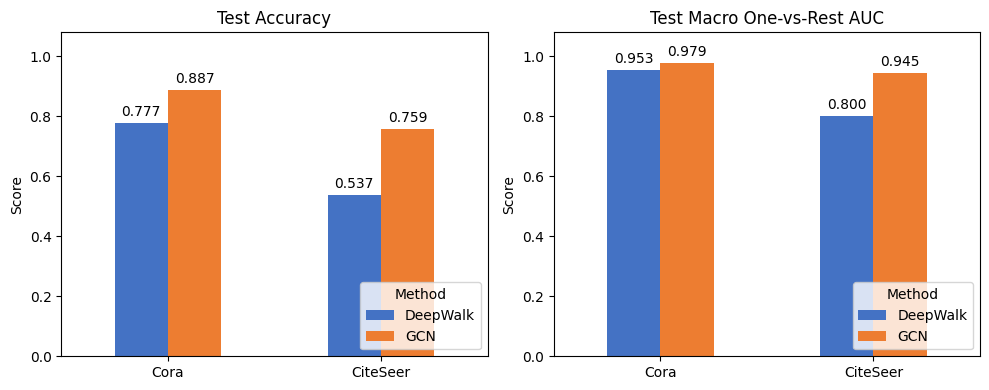

Figure saved to: C:\Users\reema\results\model_comparison.png


In [37]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, metric, title in [
    (axes[0], "Test accuracy", "Test Accuracy"),
    (axes[1], "Test AUC", "Test Macro One-vs-Rest AUC")
]:
    comparison = results_table.pivot(
        index="Dataset",
        columns="Method",
        values=metric
    ).reindex(["Cora", "CiteSeer"])

    comparison.plot.bar(
        ax=ax,
        color=["#4472C4", "#ED7D31"],
        rot=0
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.08)
    ax.legend(title="Method", loc="lower right")

    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.3f", padding=3)

fig.tight_layout()

figure_path = results_folder / "model_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()
print("Figure saved to:", figure_path.resolve())

In [36]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.2 MB 4.2 MB/s eta 0:00:02
   ------- -------------------------------- 1.6/8.2 MB 3.8 MB/s eta 0:00:02
   ---------- ----------------------------- 2.1/8.2 MB 3.9 MB/s eta 0:00:02
   ------------ --------------------------- 2.6/8.2 MB 3.4 MB/s eta 0:00:02
   --------------- ------------------------ 3.1/8.2 MB 3.0 MB/s eta 0:00:02
   --------------- ------------------------ 3.1/8.2 MB 3.0 MB/s eta 0:00:02
   ---------------- ----------------------- 3.4/8.2 MB 2.7 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.2 MB 2.4 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.2 MB 2.4 MB/s eta 0:00:02
   ------------------- -------------------- 3.9/8.2 MB 2.0 MB/s eta 0:00:03
   -------------------- -----------------

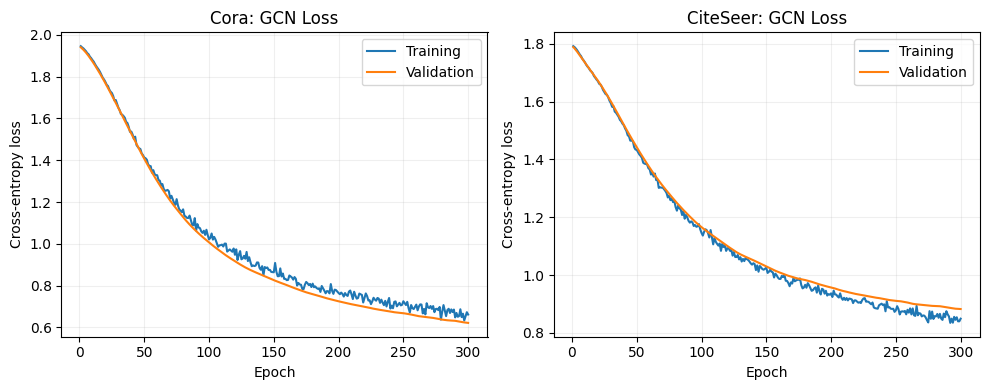

Figure saved to: C:\Users\reema\results\gcn_learning_curves.png


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, history, dataset in [
    (axes[0], gcn_history, "Cora"),
    (axes[1], citeseer_gcn_history, "CiteSeer")
]:
    epochs = range(1, len(history["train_loss"]) + 1)

    ax.plot(epochs, history["train_loss"], label="Training")
    ax.plot(epochs, history["val_loss"], label="Validation")

    ax.set_title(f"{dataset}: GCN Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()

loss_figure_path = results_folder / "gcn_learning_curves.png"
fig.savefig(loss_figure_path, dpi=300, bbox_inches="tight")

plt.show()
print("Figure saved to:", loss_figure_path.resolve())